# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión_A


**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** Dariana Montserrat Hérandez Zarate  
**Grupo:** 511 **Fecha:** 26/10/2026

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la distancia recorrida y la duración del viaje?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`trip_distance`** y **`trip_duration`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_A_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_A/
└── notebooks/
    └── Examen_A_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [35]:
# 1. Importar bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [64]:
# 2-3. Cargar el CSV (ruta relativa a la carpeta notebooks/)
ruta = "../data/raw/nyc_taxi_examen.csv"
df = pd.read_csv(ruta)
df.head(5)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,1.0,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,1.0,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,1.0,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,1.0,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,1.0,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


In [37]:
print("Dimensiones (filas, columnas):", df.shape)
print("\nNombres de las columnas:")
print(list(df.columns))

print("\nTipos de datos:")
display(df.dtypes.to_frame("tipo"))

Dimensiones (filas, columnas): (2427612, 20)

Nombres de las columnas:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'trip_duration']

Tipos de datos:


,tipo
VendorID,int64
tpep_pickup_datetime,str
tpep_dropoff_datetime,str
passenger_count,float64
trip_distance,float64
RatecodeID,float64
PULocationID,float64
DOLocationID,float64
payment_type,float64
fare_amount,float64


In [38]:
# 4. Resumen estadístico de las columnas numéricas
print("Resumen estadístico:")
display(df.describe().round(2))

Resumen estadístico:


,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
count,2427612.00,2415489.00,2415470.00,2415474.00,2415487.00,2415475.00,2415487.00,2415488.00,2415487.00,2415462.00,2415459.00,2415465.00,2415481.00,2415484.00,2415457.00,2415481.00,2415462.00,2415475.00
mean,1.89,1.30,3.30,4.23,164.14,163.22,1.17,38.53,1.57,0.48,3.67,0.59,0.99,29.38,2.25,0.20,0.56,15.61
std,0.81,1.88,5.17,17.20,62.85,69.26,0.46,542.38,1.91,0.10,4.23,2.39,0.16,25.93,0.78,0.63,0.33,260.58
min,1.00,-5.00,-99.99,1.00,1.00,1.00,1.00,-1849.60,-7.50,-0.50,-90.00,-106.46,-1.00,-1866.89,-2.50,-2.00,-0.75,-300517.52
25%,2.00,1.00,0.99,1.00,132.00,113.00,1.00,9.30,0.00,0.50,1.00,0.00,1.00,16.38,2.50,0.00,0.75,7.28
50%,2.00,1.00,1.70,1.00,161.00,162.00,1.00,13.50,1.00,0.50,2.95,0.00,1.00,21.54,2.50,0.00,0.75,12.32
75%,2.00,1.00,3.36,1.00,232.00,234.00,1.00,21.90,2.50,0.50,4.56,0.00,1.00,31.45,2.50,0.00,0.75,20.12
max,7.00,100.00,1686.49,99.00,265.00,265.00,4.00,19995.59,23.25,11.50,444.44,616.79,1.00,5530.74,2.75,27.00,0.75,8373.67


In [39]:
# 5. Valores de payment_type
print("Valores de payment_type:")
display(df["payment_type"].value_counts(dropna=False).to_frame("viajes"))

Valores de payment_type:


,viajes
payment_type,
1.0,2051983
2.0,329533
4.0,23558
NaN,12125
3.0,10413


**Observación sobre `payment_type`:** en este CSV la columna no contiene el texto `Cash`; trae **códigos numéricos** del diccionario de datos de NYC TLC (`1` = Credit card, `2` = Cash, `3` = No charge, `4` = Dispute), además de algunos nulos. Por eso, en la sección 3 convierto los códigos a texto con un diccionario y filtro exactamente `payment_type == "Cash"` (código `2`).

## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [40]:
# 1. Copia de los datos originales
df_limpio = df.copy()
print("Dimensiones antes de limpiar:", df_limpio.shape)

Dimensiones antes de limpiar: (2427612, 20)


In [41]:
# 2. Nulos por columna y duplicados ANTES de limpiar
print("\nValores nulos por columna (antes):")
display(df_limpio.isnull().sum().to_frame("nulos"))
print("Registros duplicados (antes):", df_limpio.duplicated().sum())


Valores nulos por columna (antes):


,nulos
VendorID,0
tpep_pickup_datetime,12126
tpep_dropoff_datetime,12127
passenger_count,12123
trip_distance,12142
RatecodeID,12138
PULocationID,12125
DOLocationID,12137
payment_type,12125
fare_amount,12124


Registros duplicados (antes): 11961


In [42]:
# 3. Eliminar duplicados y filas con nulos
df_limpio = df_limpio.drop_duplicates()
print("\nDespués de eliminar duplicados:", df_limpio.shape)

df_limpio = df_limpio.dropna()
print("Después de eliminar nulos:", df_limpio.shape)


Después de eliminar duplicados: (2415651, 20)
Después de eliminar nulos: (2196158, 20)


In [43]:
# 4. Conservar solo los registros que cumplen TODAS las condiciones
condiciones = (
    (df_limpio["trip_distance"] > 0)
    & (df_limpio["passenger_count"] > 0) & (df_limpio["passenger_count"] < 100)
    & (df_limpio["fare_amount"] > 0) & (df_limpio["fare_amount"] < 10000)
    & (df_limpio["trip_duration"] > 0)
)
df_limpio = df_limpio[condiciones].copy()

In [44]:
# 5. Registros que quedan
print("\nDimensiones después de limpiar:", df_limpio.shape)
print("Registros eliminados en total:", len(df) - len(df_limpio))

# Verificación de las condiciones y de la ausencia de nulos/duplicados
print("\nVerificación:")
print("Nulos restantes:", int(df_limpio.isnull().sum().sum()))
print("Duplicados restantes:", int(df_limpio.duplicated().sum()))
print("trip_distance mínimo:", df_limpio["trip_distance"].min())
print("passenger_count rango:", df_limpio["passenger_count"].min(), "-", df_limpio["passenger_count"].max())
print("fare_amount rango:", round(df_limpio["fare_amount"].min(), 2), "-", round(df_limpio["fare_amount"].max(), 2))
print("trip_duration mínimo:", round(df_limpio["trip_duration"].min(), 4))


Dimensiones después de limpiar: (2096600, 20)
Registros eliminados en total: 331012

Verificación:
Nulos restantes: 0
Duplicados restantes: 0
trip_distance mínimo: 0.01
passenger_count rango: 1.0 - 8.0
fare_amount rango: 0.01 - 1860.8
trip_duration mínimo: 0.0167


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`trip_distance`** y **`trip_duration`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [45]:
# En el CSV, payment_type viene como código numérico del diccionario de datos
# de NYC TLC: 1 = Credit card, 2 = Cash, 3 = No charge, 4 = Dispute.
codigos_pago = {1: "Credit card", 2: "Cash", 3: "No charge", 4: "Dispute"}
df_limpio["payment_type"] = df_limpio["payment_type"].map(codigos_pago)

print("Tipos de pago después de limpiar:")
display(df_limpio["payment_type"].value_counts(dropna=False).to_frame("viajes"))

# 1. Filtrar solo los viajes pagados en efectivo
df_cash = df_limpio[df_limpio["payment_type"] == "Cash"].copy()


Tipos de pago después de limpiar:


,viajes
payment_type,
Credit card,1799462
Cash,282085
Dispute,9753
No charge,5300


In [46]:
# 2. Seleccionar únicamente las dos variables del agrupamiento
X = df_cash[["trip_distance", "trip_duration"]].copy()

In [47]:
# 3. Cantidad de viajes y estadísticas descriptivas
print("Cantidad de viajes en efectivo:", len(df_cash))
display(X.describe().round(2))

Cantidad de viajes en efectivo: 282085


,trip_distance,trip_duration
count,282085.00,282085.00
mean,3.84,17.51
std,6.21,40.68
min,0.01,0.03
25%,0.92,7.40
50%,1.70,12.42
75%,4.37,20.88
max,1686.49,8373.67


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [48]:
# 1. Transformación logarítmica log(1 + x)
X_log = np.log1p(X)

In [49]:
# 2-3. Estandarización (media 0, desviación estándar 1)
escalador = StandardScaler()
X_escalado = pd.DataFrame(
    escalador.fit_transform(X_log),
    columns=X.columns,
    index=X.index
)

In [50]:
# 4. Verificación del resultado
print("Variables transformadas con log1p (X_log):")
display(X_log.describe().round(4))

print("Variables estandarizadas (X_escalado):")
display(X_escalado.describe().round(4))

Variables transformadas con log1p (X_log):


,trip_distance,trip_duration
count,282085.0000,282085.0000
mean,1.2255,2.6076
std,0.7633,0.7445
min,0.0100,0.0328
25%,0.6523,2.1282
50%,0.9933,2.5965
75%,1.6808,3.0857
max,7.4310,9.0330


Variables estandarizadas (X_escalado):


,trip_distance,trip_duration
count,282085.0000,282085.0000
mean,0.0000,-0.0000
std,1.0000,1.0000
min,-1.5924,-3.4587
25%,-0.7509,-0.6439
50%,-0.3042,-0.0149
75%,0.5966,0.6422
max,8.1299,8.6310


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

In [51]:
valores_k = [2, 3, 4, 5, 6]
inercias = []
siluetas = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas_k = modelo.fit_predict(X_escalado)

    inercias.append(modelo.inertia_)
    siluetas.append(
        silhouette_score(X_escalado, etiquetas_k, sample_size=5000, random_state=42)
    )

# Tabla comparativa
resultados_k = pd.DataFrame({"k": valores_k, "Inercia": inercias, "Silueta": siluetas})
display(resultados_k.round(4))

,k,Inercia,Silueta
0,2,227681.2292,0.5320
1,3,137511.9588,0.4478
2,4,100620.1949,0.4191
3,5,79205.3717,0.3894
4,6,66980.3104,0.3737


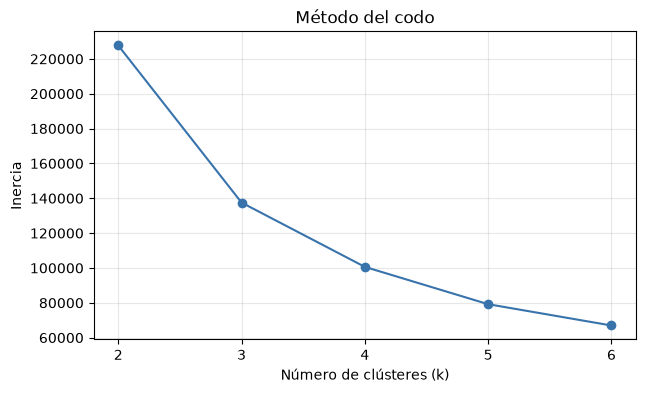

In [52]:
# Gráfica 1: método del codo
plt.figure(figsize=(7, 4))

plt.plot(resultados_k["k"], resultados_k["Inercia"], marker="o", color="#3973ac")
plt.title("Método del codo")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(valores_k)
plt.grid(alpha=0.3)
plt.show()

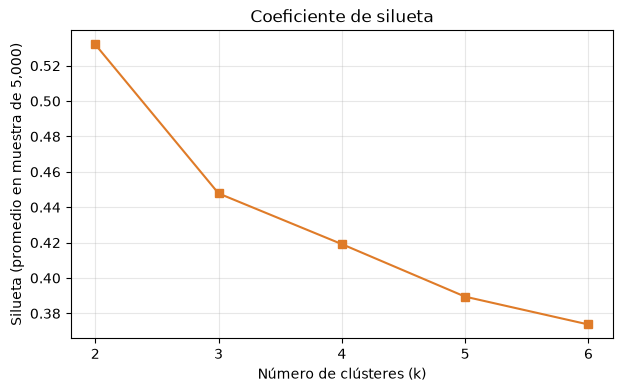

In [59]:
# Gráfica 2: coeficiente de silueta
plt.figure(figsize=(7, 4))

plt.plot(resultados_k["k"], resultados_k["Silueta"], marker="s", color="#df7b28")
plt.title("Coeficiente de silueta")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Silueta (promedio en muestra de 5,000)")
plt.xticks(valores_k)
plt.grid(alpha=0.3)
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`trip_distance`**, eje Y = **`trip_duration`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

In [60]:
# 1. Valor de k elegido a partir de las métricas anteriores (justificación en la Parte B)
k_elegido = 3

In [61]:
# 2. Modelo final
modelo_final = KMeans(n_clusters=k_elegido, random_state=42, n_init=10)

In [62]:
# 3. Etiquetas de clúster para cada viaje
etiquetas = modelo_final.fit_predict(X_escalado)
print("Viajes por clúster:")
display(pd.Series(etiquetas).value_counts().sort_index().to_frame("viajes"))

Viajes por clúster:


,viajes
0,62395
1,125521
2,94169


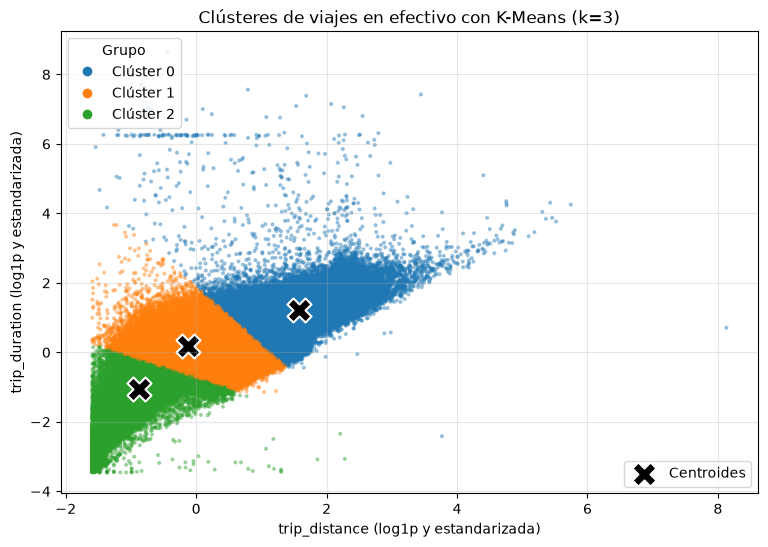

In [63]:
# 4-7. Dispersión con clústeres y centroides (espacio transformado y estandarizado)
plt.figure(figsize=(9, 6))
dispersion = plt.scatter(
    X_escalado["trip_distance"], X_escalado["trip_duration"],
    c=etiquetas, cmap="tab10", s=4, alpha=0.35, vmin=-0.5, vmax=9.5
)

centroides = modelo_final.cluster_centers_
plt.scatter(
    centroides[:, 0], centroides[:, 1],
    marker="X", s=300, color="black", edgecolor="white", linewidth=1.5,
    label="Centroides"
)

plt.title(f"Clústeres de viajes en efectivo con K-Means (k={k_elegido})")
plt.xlabel("trip_distance (log1p y estandarizada)")
plt.ylabel("trip_duration (log1p y estandarizada)")
handles = [plt.Line2D([0], [0], marker="o", linestyle="", color=plt.get_cmap("tab10")(i)) for i in range(k_elegido)]
leyenda_clusters = plt.legend(handles, [f"Clúster {i}" for i in range(k_elegido)], title="Grupo", loc="upper left")
plt.gca().add_artist(leyenda_clusters)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `trip_distance`.
   - **Media y mediana** de `trip_duration`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: millas para la distancia y minutos para la duración.

**Evidencia:** tabla de estadísticos por clúster.

In [58]:
# 1-2. DataFrame con las unidades ORIGINALES y la etiqueta del clúster
df_resultado = df_cash.copy()
df_resultado["cluster"] = etiquetas

# 3. Estadísticos por clúster (datos originales: millas y minutos)
tabla_clusters = df_resultado.groupby("cluster").agg(
    viajes=("cluster", "size"),
    distancia_media_millas=("trip_distance", "mean"),
    distancia_mediana_millas=("trip_distance", "median"),
    duracion_media_min=("trip_duration", "mean"),
    duracion_mediana_min=("trip_duration", "median"),
)

# 4. Tabla con dos decimales
tabla_clusters["porcentaje_viajes"] = tabla_clusters["viajes"] / len(df_resultado) * 100
display(tabla_clusters.round(2))

,viajes,distancia_media_millas,distancia_mediana_millas,duracion_media_min,duracion_mediana_min,porcentaje_viajes
cluster,,,,,,
0,62395,11.55,9.81,39.48,31.40,22.12
1,125521,2.30,1.94,15.43,14.00,44.50
2,94169,0.80,0.76,5.72,5.82,33.38


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:** 

Elegí k = 3 porque permite dividir los viajes en tres grupos: cortos, medianos y largos. La inercia disminuye bastante al pasar de 2 a 3 grupos, pero al agregar más grupos la mejora es cada vez menor. Aunque la silueta es más alta con k = 2 (0.532), con k = 3 sigue siendo aceptable (0.448). Además, tres grupos permiten entender mejor las diferencias entre los viajes. Por eso considero que k = 3 es la mejor opción, ya que ofrece un buen equilibrio entre la calidad de los grupos y la facilidad para interpretarlos.


**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:**

\- Clúster 2 — “Viajes cortos” (94,169 viajes, 33.4%). Son los viajes más cortos, con una distancia promedio de 0.80 millas y una duración de 5.72 minutos. La media y la mediana son muy parecidas, por lo que los viajes de este grupo tienen características similares.

\- Clúster 1 — “Viajes medios” (125,521 viajes, 44.5%). Es el grupo más numeroso. Sus viajes tienen una distancia promedio de 2.30 millas y duran alrededor de 15.43 minutos. Representa los trayectos de duración y distancia intermedias.

\- Clúster 0 — “Viajes largos” (62,395 viajes, 22.1%). Son los viajes más largos, con una distancia promedio de 11.55 millas y una duración de 39.48 minutos. La media es mayor que la mediana porque algunos viajes muy largos aumentan el promedio. Podrían incluir trayectos hacia zonas alejadas, aunque no se puede confirmar solo con estos datos.


**Pregunta 3 — Análisis sencillo.** ¿Qué clúster presenta la mayor duración promedio? ¿También tiene la mayor distancia promedio? Explica usando la tabla.

**Respuesta:** 

El **clúster 0** tiene la mayor duración promedio y también tiene la mayor distancia promedio. En la tabla se ve que las dos variables crecen juntas de un grupo a otro: duración de 5.72 → 15.43 → 39.48 minutos y distancia de 0.80 → 2.30 → 11.55 millas al pasar del clúster 2 al 1 y al 0. Es lo esperado, pues los viajes más largos en distancia suelen tardar más.


**Pregunta 4 — Análisis sencillo.** ¿Cuál es el grupo más numeroso? ¿Qué características de distancia y duración predominan en ese grupo?

**Respuesta:** 

El grupo más numeroso es el clúster 1 con 125,521 viajes (44.5% de los viajes en efectivo). Predominan los viajes de distancia y duración intermedias: unas 2.30 millas en promedio (mediana 1.94) y alrededor de 15 minutos (media 15.43, mediana 14.00), es decir, trayectos urbanos de recorrido medio, ni muy breves ni muy largos.


---
### Lista de verificación antes de entregar

- [x] Se muestran la carga, exploración, limpieza y filtrado.
- [x] Se utilizaron las **dos variables indicadas**.
- [x] Se aplicaron `log1p` y `StandardScaler`.
- [x] Se calcularon inercia y silueta para `k = 2...6`.
- [x] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [x] Se visualizan los clústeres y sus centroides.
- [x] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [x] Se respondieron las cuatro preguntas finales.

NOTA: No conteste la primer preegunta porque no encontre insdriccuiones que mensionen que deberia de contestarla

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**